<a href="https://colab.research.google.com/github/Ferdisalah/LPCVC_2026/blob/main/GCI%202026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [18]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [19]:
%cd "/content/drive/MyDrive/Competition"

/content/drive/MyDrive/Competition


In [20]:
import os
from pathlib import Path
# Automatically get the current working directory
current_dir = Path(os.getcwd())
# Define file paths using pathlib
train_file = current_dir / "input" / "train.csv"
test_file = current_dir / "input" / "test.csv"
sample_sub_file = current_dir / "input" / "sample_submission.csv"
# Check if path exists
if train_file.exists() and test_file.exists() and sample_sub_file.exists():
 print("All files exist and path is correctly set.")
else:
 print("Some files are missing or path is not correctly set.")

All files exist and path is correctly set.


In [21]:
train = pd.read_csv(train_file)
test = pd.read_csv(test_file)
sample_sub = pd.read_csv(sample_sub_file)

In [22]:
# Check train data
print(f"train shape: {train.shape}")
train.head(3)
# Check test data
#print(f"test shape: {test.shape}")
#test.head(3)


train shape: (171202, 34)


,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,TARGET
0,0,Cash loans,F,0,112500.0,755190.0,36328.5,675000.0,Working,Higher education,...,School,NaN,0.372591,NaN,-292.0,NaN,NaN,NaN,NaN,0
1,1,Cash loans,F,0,225000.0,585000.0,16893.0,585000.0,Pensioner,Secondary / secondary special,...,XNA,NaN,0.449567,0.553165,-617.0,0.0,0.0,0.0,1.0,0
2,2,Cash loans,F,0,54000.0,334152.0,18256.5,270000.0,State servant,Secondary / secondary special,...,Postal,NaN,0.569503,NaN,-542.0,NaN,NaN,NaN,NaN,0


In [23]:
# Focus on 5 features
use_features = [
 "NAME_CONTRACT_TYPE",
 "AMT_INCOME_TOTAL",
 "EXT_SOURCE_2",
 "OWN_CAR_AGE",
 "ORGANIZATION_TYPE",
 "AMT_CREDIT"	,
 "AMT_ANNUITY",
 "AMT_GOODS_PRICE",

 # add new features to use here
]
target = train["TARGET"].values
train = train[use_features]
train["TARGET"] = target
test = test[use_features]
# Check train data
print(f"train shape: {train.shape}")
train.head(3)
# Check test data
print(f"test shape: {test.shape}")
test.head(3)

train shape: (171202, 9)
test shape: (61500, 8)


,NAME_CONTRACT_TYPE,AMT_INCOME_TOTAL,EXT_SOURCE_2,OWN_CAR_AGE,ORGANIZATION_TYPE,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE
0,Cash loans,144000.0,0.720416,NaN,Kindergarten,961146.0,28233.0,688500.0
1,Cash loans,103500.0,0.287306,NaN,School,296280.0,16069.5,225000.0
2,Cash loans,180000.0,0.352456,NaN,Trade: type 7,183694.5,11236.5,139500.0


In [24]:
# Check missing values of train data
train.isnull().sum()
# Check missing values of test data
test.isnull().sum()

,0
NAME_CONTRACT_TYPE,0
AMT_INCOME_TOTAL,0
EXT_SOURCE_2,130
OWN_CAR_AGE,40909
ORGANIZATION_TYPE,0
AMT_CREDIT,0
AMT_ANNUITY,0
AMT_GOODS_PRICE,0


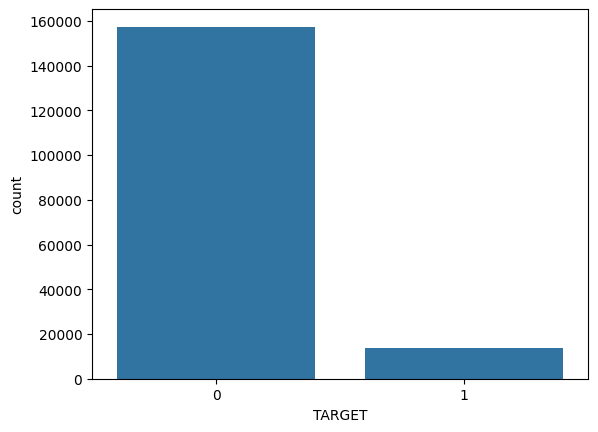

In [25]:
# The distribution of the target (default or not)
sns.countplot(data=train, x="TARGET")
plt.show()


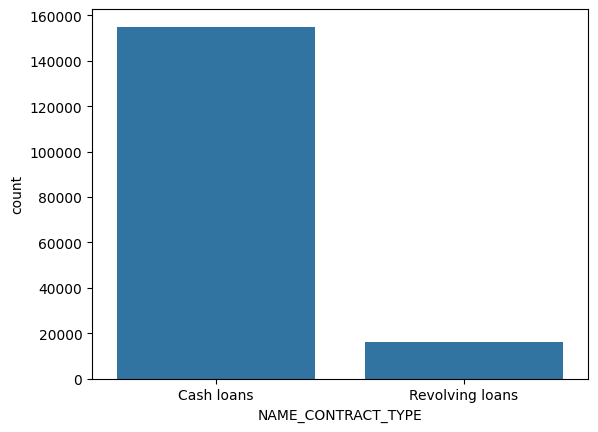

In [26]:
# The distribution of NAME_CONTRACT_TYPE
sns.countplot(data=train, x="NAME_CONTRACT_TYPE")
plt.show()


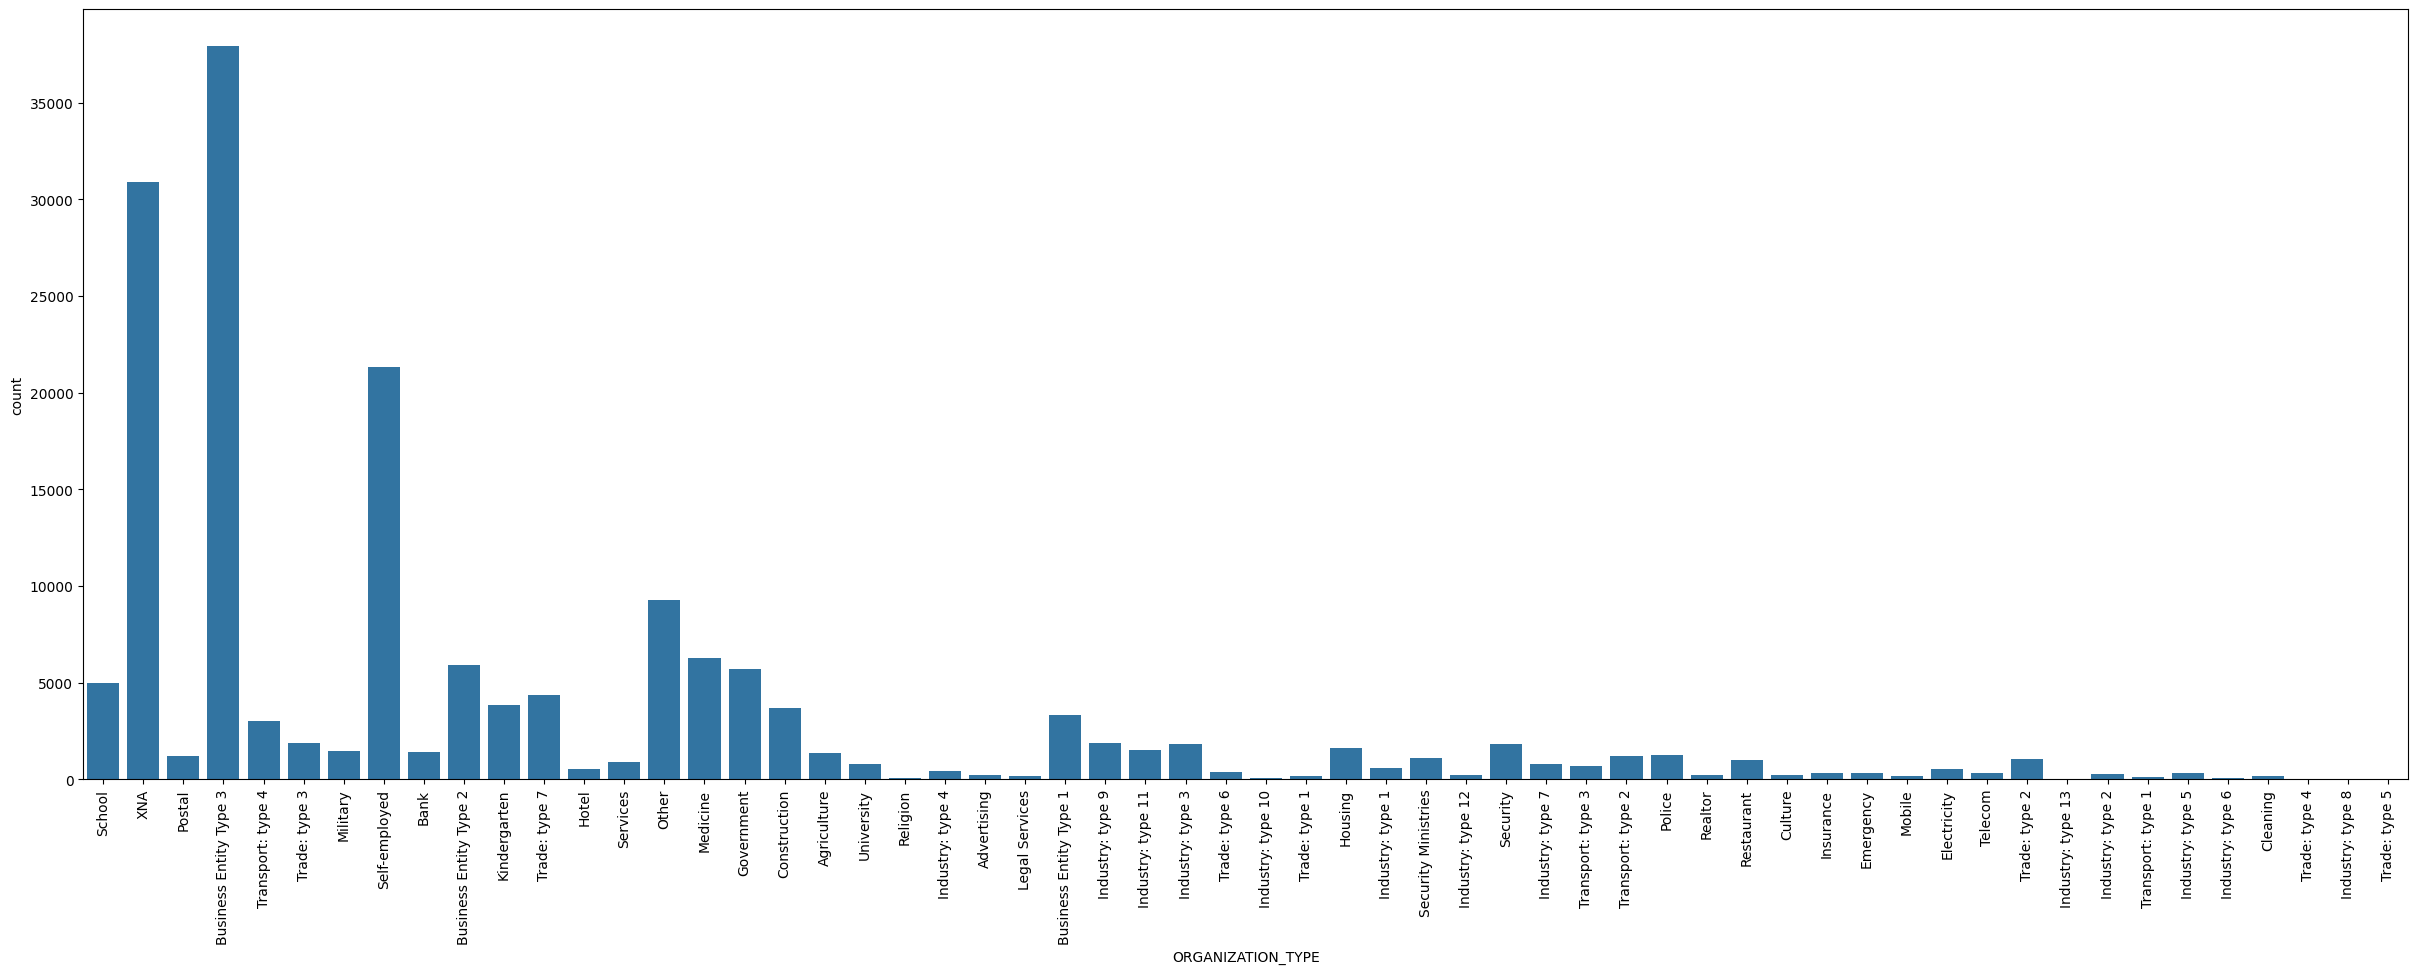

In [27]:
# The distribution of ORGANIZATION_TYPE
plt.figure(figsize=(30, 10))
sns.countplot(data=train, x="ORGANIZATION_TYPE")
plt.tick_params(axis="x", rotation=90)
plt.show()


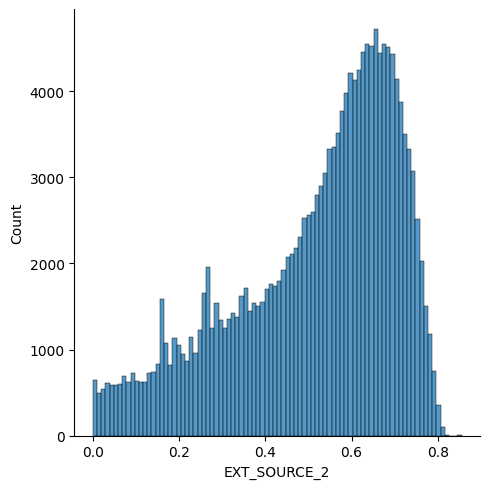

In [28]:
# The distribution of EXT_SOURCE_2
sns.displot(data=train, x="EXT_SOURCE_2")
plt.show()

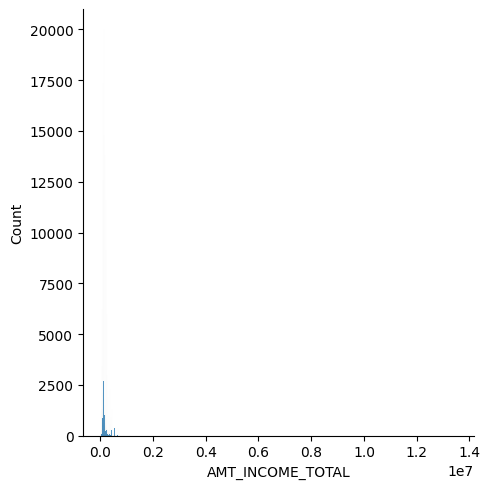

In [29]:
# The distribution of AMT_INCOME_TOTAL
sns.displot(data=train, x="AMT_INCOME_TOTAL")
plt.show()

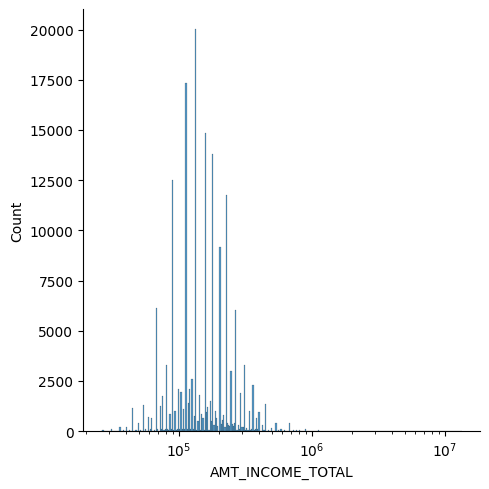

In [30]:
# The distribution of AMT_INCOME_TOTAL（Logarithmic transformation）
sns.displot(data=train, x="AMT_INCOME_TOTAL", log_scale=10)
plt.show()


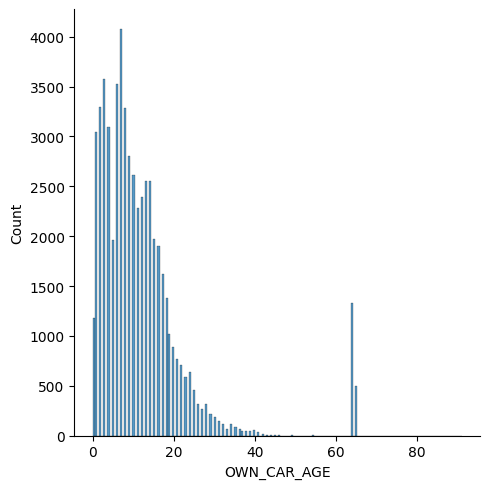

In [31]:
# Check the type of AMT_INCOME_TOTAL values
len(train["AMT_INCOME_TOTAL"].unique())
# Top 10 values of AMT_INCOME_TOTAL
train["AMT_INCOME_TOTAL"].value_counts().head(10)
# The distribution of OWN_CAR_AGE
sns.displot(data=train, x="OWN_CAR_AGE")
plt.show()



In [32]:
# Numerization of NAME_CONTRACT_TYPE（Label Encoding）
train["NAME_CONTRACT_TYPE"].replace({'Cash loans': 0, 'Revolving loans': 1}, inplace=True)
test["NAME_CONTRACT_TYPE"].replace({'Cash loans': 0, 'Revolving loans': 1}, inplace=True)
train.head(5)

,NAME_CONTRACT_TYPE,AMT_INCOME_TOTAL,EXT_SOURCE_2,OWN_CAR_AGE,ORGANIZATION_TYPE,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,TARGET
0,0,112500.0,0.372591,NaN,School,755190.0,36328.5,675000.0,0
1,0,225000.0,0.449567,NaN,XNA,585000.0,16893.0,585000.0,0
2,0,54000.0,0.569503,NaN,Postal,334152.0,18256.5,270000.0,0
3,0,67500.0,0.105235,NaN,XNA,152820.0,8901.0,135000.0,0
4,0,157500.0,0.202490,NaN,Business Entity Type 3,271066.5,21546.0,234000.0,1


In [33]:
# Numerization of ORGANIZATION_TYPE (Count Encoding）
organization_ce = train["ORGANIZATION_TYPE"].value_counts()
train["ORGANIZATION_TYPE"] =train["ORGANIZATION_TYPE"].map(organization_ce)
test["ORGANIZATION_TYPE"] =test["ORGANIZATION_TYPE"].map(organization_ce)
train.head(5)


,NAME_CONTRACT_TYPE,AMT_INCOME_TOTAL,EXT_SOURCE_2,OWN_CAR_AGE,ORGANIZATION_TYPE,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,TARGET
0,0,112500.0,0.372591,NaN,4991,755190.0,36328.5,675000.0,0
1,0,225000.0,0.449567,NaN,30898,585000.0,16893.0,585000.0,0
2,0,54000.0,0.569503,NaN,1185,334152.0,18256.5,270000.0,0
3,0,67500.0,0.105235,NaN,30898,152820.0,8901.0,135000.0,0
4,0,157500.0,0.202490,NaN,37943,271066.5,21546.0,234000.0,1


In [34]:
# Complete missing values of EXT_SOURCE_2 with the average
train["EXT_SOURCE_2"].fillna(train["EXT_SOURCE_2"].mean(),inplace=True)
test["EXT_SOURCE_2"].fillna(train["EXT_SOURCE_2"].mean(),inplace=True) # Use average of train data to fill test data
train.isnull().sum()

,0
NAME_CONTRACT_TYPE,0
AMT_INCOME_TOTAL,0
EXT_SOURCE_2,0
OWN_CAR_AGE,112992
ORGANIZATION_TYPE,0
AMT_CREDIT,0
AMT_ANNUITY,0
AMT_GOODS_PRICE,0
TARGET,0


In [35]:
# Treat values above 60 (outliers) in OWN_CAR_AGE as missing values
train.loc[train["OWN_CAR_AGE"] >= 60, "OWN_CAR_AGE"] = np.nan
test.loc[test["OWN_CAR_AGE"] >= 60, "OWN_CAR_AGE"] = np.nan

In [36]:
# Divide OWN_CAR_AGE into groups
train["OWN_CAR_AGE"] = train["OWN_CAR_AGE"] // 10
test["OWN_CAR_AGE"] = test["OWN_CAR_AGE"] // 10
train["OWN_CAR_AGE"].unique()
# Apply One Hot Encoding to OWN_CAR_AGE
train_car_age_ohe =pd.get_dummies(train["OWN_CAR_AGE"]).add_prefix("OWN_CAR_AGE_")
test_car_age_ohe =pd.get_dummies(test["OWN_CAR_AGE"]).add_prefix("OWN_CAR_AGE_")
# Add the one hot encoded columns to train/test
train = pd.concat([train, train_car_age_ohe], axis=1)
test = pd.concat([test, test_car_age_ohe], axis=1)
# Remove original OWN_CAR_AGE
train.drop('OWN_CAR_AGE', axis=1, inplace=True)
test.drop('OWN_CAR_AGE', axis=1, inplace=True)
train.head(5)

,NAME_CONTRACT_TYPE,AMT_INCOME_TOTAL,EXT_SOURCE_2,ORGANIZATION_TYPE,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,TARGET,OWN_CAR_AGE_0.0,OWN_CAR_AGE_1.0,OWN_CAR_AGE_2.0,OWN_CAR_AGE_3.0,OWN_CAR_AGE_4.0,OWN_CAR_AGE_5.0
0,0,112500.0,0.372591,4991,755190.0,36328.5,675000.0,0,False,False,False,False,False,False
1,0,225000.0,0.449567,30898,585000.0,16893.0,585000.0,0,False,False,False,False,False,False
2,0,54000.0,0.569503,1185,334152.0,18256.5,270000.0,0,False,False,False,False,False,False
3,0,67500.0,0.105235,30898,152820.0,8901.0,135000.0,0,False,False,False,False,False,False
4,0,157500.0,0.202490,37943,271066.5,21546.0,234000.0,1,False,False,False,False,False,False


In [37]:
# Importing libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score
# Split the data into explanatory and target variables
X = train.drop("TARGET", axis=1).values
y = train["TARGET"].values
X_test = test.values
# Standardization
sc = StandardScaler()
sc.fit(X)
X_std = sc.transform(X)
X_test_std = sc.transform(X_test)


In [38]:
# Split the original data into the training data and the validation data
X_train, X_valid, y_train, y_valid = train_test_split(X_std, y,test_size=0.3, stratify=y, random_state=0)


In [39]:
# Logistic Regression
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression(random_state=0)
lr.fit(X_train, y_train)
lr_train_pred = lr.predict_proba(X_train)[:, 1]
lr_valid_pred = lr.predict_proba(X_valid)[:, 1]
print(f"Train Score: {roc_auc_score(y_train, lr_train_pred)}")
print(f"Valid Score: {roc_auc_score(y_valid, lr_valid_pred)}")
# Random Forest
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(random_state=0, max_depth=10)
rf.fit(X_train, y_train)
rf_train_pred = rf.predict_proba(X_train)[:, 1]
rf_valid_pred = rf.predict_proba(X_valid)[:, 1]
print(f"Train Score: {roc_auc_score(y_train, rf_train_pred)}")
print(f"Valid Score: {roc_auc_score(y_valid, rf_valid_pred)}")
# XGBoost
from xgboost import XGBClassifier

xgb = XGBClassifier(random_state=0, max_depth=3, eval_metric='auc')
xgb.fit(X_train, y_train)

xgb_train_pred = xgb.predict_proba(X_train)[:, 1]
xgb_valid_pred = xgb.predict_proba(X_valid)[:, 1]

print(f"Train Score: {roc_auc_score(y_train, xgb_train_pred)}")
print(f"Valid Score: {roc_auc_score(y_valid, xgb_valid_pred)}")

Train Score: 0.6701604968138053
Valid Score: 0.6745372787669219
Train Score: 0.7836055234663255
Valid Score: 0.6945295787725566
Train Score: 0.7272553244877673
Valid Score: 0.704844077029777


In [40]:
train_pred = (lr_train_pred + rf_train_pred) / 2
valid_pred = (lr_valid_pred + rf_valid_pred) / 2
print(f"Train Score: {roc_auc_score(y_train, train_pred)}")
print(f"Valid Score: {roc_auc_score(y_valid, valid_pred)}")

Train Score: 0.7388392635196845
Valid Score: 0.690724186181399


In [41]:
# If logistic regression model was better
pred = lr.predict_proba(X_test_std)[:, 1]
# Make predictions for the test data
# Change model name if needed
pred = rf.predict_proba(X_test_std)[:, 1]
# Put the prediction into the format of submission
sample_sub['TARGET'] = pred
sample_sub
# Create the "output" directory if it doesn't exist
output_dir = current_dir / "output"
os.makedirs(output_dir, exist_ok=True)
# Specify the new output file path
output_file = output_dir / "submission.csv"
# Save the CSV file to the "output" directory
sample_sub.to_csv(output_file, index=False)
# If XGBoost model was better
# Make predictions for the test data
pred = xgb.predict_proba(X_test_std)[:, 1]

# Put the prediction into the format of submission
sample_sub['TARGET'] = pred
sample_sub

# Create the "output" directory if it doesn't exist
output_dir = current_dir / "output"
os.makedirs(output_dir, exist_ok=True)

# Specify the new output file path
output_file = output_dir / "submission.csv"

# Save the CSV file to the "output" directory
sample_sub.to_csv(output_file, index=False)



In [42]:
import zipfile
from pathlib import Path

# Define directory and file names
current_dir = Path.cwd()  # Or specify your directory, e.g., Path("/path/to/folder")
notebook_filename = "tutorial.ipynb"
zip_filename = "tutorial.zip"

# Define the full paths using current_dir
notebook_path = current_dir / notebook_filename
zip_output_path = current_dir / zip_filename

# Check if the notebook file exists and create the ZIP file
if notebook_path.exists():
    with zipfile.ZipFile(zip_output_path, "w", zipfile.ZIP_DEFLATED) as zipf:
        # Add the notebook to the ZIP file (arcname avoids including the full folder structure)
        zipf.write(notebook_path, arcname=notebook_filename)
    print(f"Successfully created: {zip_output_path}")
else:
    print(f"Error: Could not find '{notebook_filename}' in {current_dir}.")
    print("Please check if the notebook name and the current directory are correct.")

Successfully created: /content/drive/MyDrive/Competition/tutorial.zip
